
H2 Model Performance and Robustness Validation

H2: A Random Forest model provides the highest spoofing detection accuracy in IoT baggage tracking data compared to other Machine Learning models.

RQ2: Which Machine Learning models are most effective at detecting spoofing in Internet of Things enabled baggage tracking data?

This supplemental analysis checks the original H2 results against a majority class baseline, examines incorrect spoofing alerts, and evaluates whether adjusting the Random Forest prediction threshold changes performance. It uses the same prepared RFID dataset and reproduces the working spoofing patterns from Notebook 04.

The baggage journey split is maintained to prevent records from the same journey appearing in both training and testing. Threshold selection uses only a separate validation portion of the training data. The held out test population is used for final evaluation.

The negative class includes all records without the spoofing label, including other abnormal conditions. The experiment is limited to simulated RFID baggage scan data.

An additional challenge removes one simulated spoofing pattern from training at a time, then evaluates the models on that excluded pattern. This tests unfamiliar conditions within the simulated data and does not represent independently collected attacks.


In [1]:

# Step 1: Connect and review the H2 research data

# Load the libraries

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the main research folder

here = Path.cwd()

main_folder = next(
    (
        folder
        for folder in [here, *here.parents]
        if (
            folder / "06_Prepared_Data/02_Prepared_RFID_Data.csv"
        ).exists()
    ),
    None
)

# Confirm the dataset can be located

if main_folder is None:
    raise FileNotFoundError(
        "The prepared RFID data file was not found."
    )

# Set the existing research locations

prepared_file = (
    main_folder / "06_Prepared_Data/02_Prepared_RFID_Data.csv"
)

results_folder = main_folder / "08_H2_Results"

# Load the original prepared RFID data

h2_data = pd.read_csv(prepared_file)

# Check the required data fields

required = [
    "bag_id",
    "scan_id",
    "spoofing_label",
    "reader_id",
    "expected_reader_id",
    "reader_location",
    "expected_reader_location",
    "timestamp",
    "expected_timestamp",
    "actual_sequence",
    "expected_sequence",
    "location_match",
    "route_type",
    "scan_status"
]

missing = [
    name
    for name in required
    if name not in h2_data.columns
]

if missing:
    raise ValueError(
        "Missing required RFID columns: " + str(missing)
    )

# Check that scan IDs are unique

assert h2_data["scan_id"].is_unique

# Confirm the spoofing labels are valid

assert h2_data["spoofing_label"].isin([0, 1]).all()

# Display the original data information

print("RFID records:", len(h2_data))

print(
    "Baggage journeys:",
    h2_data["bag_id"].nunique()
)

print(
    "Spoofing records:",
    int(h2_data["spoofing_label"].sum())
)

print(
    "Non spoofing records:",
    int((h2_data["spoofing_label"] == 0).sum())
)

print("\nStep 1 complete.")


RFID records: 31575
Baggage journeys: 5000
Spoofing records: 375
Non spoofing records: 31200

Step 1 complete.



Step 2: Recreate the H2 Working Spoofing Data

Notebook 04 changed a working copy of the spoofed records to represent unauthorized reader, cloned reader location, and replayed timing patterns. Those changes were not written back to the prepared CSV. The same random seed and transformation logic are used here so that Notebook 12 examines the same H2 experiment rather than a newly invented dataset.

The spoofing pattern is used only to examine results. It is excluded from the model predictors.


In [2]:

# Step 2: Recreate the H2 working spoofing data

# Create a separate working copy

h2_model_data = h2_data.copy()

# Convert the timestamp fields

h2_model_data["timestamp"] = pd.to_datetime(
    h2_model_data["timestamp"]
)

h2_model_data["expected_timestamp"] = pd.to_datetime(
    h2_model_data["expected_timestamp"]
)

# Set the approved RFID reader identities

approved_readers = [
    "RDR001", "RDR002", "RDR003", "RDR004",
    "RDR005", "RDR006", "RDR007"
]

# Use the same random state as Notebook 04

rng = np.random.default_rng(42)

# Find and shuffle the spoofing records

spoofed_indices = h2_model_data.index[
    h2_model_data["spoofing_label"] == 1
].to_numpy().copy()

rng.shuffle(spoofed_indices)

# Divide the records into three attack patterns

unauthorized, cloned_location, replayed_timing = (
    np.array_split(spoofed_indices, 3)
)

# Identify the three spoofing patterns

h2_model_data["spoofing_pattern"] = "Non Spoofing"

h2_model_data.loc[
    unauthorized, "spoofing_pattern"
] = "Unauthorized Reader"

h2_model_data.loc[
    cloned_location, "spoofing_pattern"
] = "Cloned Reader Location"

h2_model_data.loc[
    replayed_timing, "spoofing_pattern"
] = "Replayed Reader Timing"

# Create unauthorized reader activity

for row in unauthorized:

    expected = h2_model_data.loc[
        row, "expected_reader_id"
    ]

    choices = [
        reader
        for reader in approved_readers
        if reader != expected
    ]

    h2_model_data.loc[
        row, "reader_id"
    ] = rng.choice(choices)

# Identify valid reader locations

valid_locations = h2_model_data.loc[
    (h2_model_data["spoofing_label"] == 0)
    & (h2_model_data["location_match"] == 1),
    "reader_location"
].dropna().unique().tolist()

# Create cloned reader location activity

for row in cloned_location:

    expected = h2_model_data.loc[
        row, "expected_reader_id"
    ]

    location = h2_model_data.loc[
        row, "expected_reader_location"
    ]

    h2_model_data.loc[
        row, "reader_id"
    ] = expected

    choices = [
        item
        for item in valid_locations
        if item != location
    ]

    if not choices:
        raise ValueError(
            "No alternate reader locations were available."
        )

    h2_model_data.loc[
        row, "reader_location"
    ] = rng.choice(choices)

# Create replayed reader timing activity

for row in replayed_timing:

    h2_model_data.loc[
        row, "reader_id"
    ] = h2_model_data.loc[
        row, "expected_reader_id"
    ]

    h2_model_data.loc[
        row, "reader_location"
    ] = h2_model_data.loc[
        row, "expected_reader_location"
    ]

    offset = int(rng.integers(5, 10))

    h2_model_data.loc[
        row, "timestamp"
    ] = (
        h2_model_data.loc[
            row, "expected_timestamp"
        ]
        + pd.Timedelta(minutes=offset)
    )

# Recalculate the reader comparison

h2_model_data["reader_match"] = (
    h2_model_data["reader_id"]
    == h2_model_data["expected_reader_id"]
).astype(int)

# Recalculate the location comparison

h2_model_data["location_match"] = (
    h2_model_data["reader_location"]
    == h2_model_data["expected_reader_location"]
).astype(int)

# Recalculate the sequence comparison

h2_model_data["sequence_match"] = (
    h2_model_data["actual_sequence"]
    == h2_model_data["expected_sequence"]
).astype(int)

# Recalculate the timing difference

h2_model_data["time_difference_minutes"] = (
    (
        h2_model_data["timestamp"]
        - h2_model_data["expected_timestamp"]
    ).dt.total_seconds().abs() / 60
)

# Update the delayed scan indicator

h2_model_data["delayed_indicator"] = (
    h2_model_data["time_difference_minutes"] > 15
).astype(int)

# Sort the baggage records

h2_model_data = h2_model_data.sort_values(
    ["bag_id", "timestamp", "scan_id"]
).copy()

# Recalculate the time between scans

h2_model_data["scan_gap_minutes"] = (
    h2_model_data.groupby("bag_id")["timestamp"]
    .diff().dt.total_seconds() / 60
)

# Review the working records

print("H2 working records:", len(h2_model_data))

print("\nSpoofing patterns:")

print(
    h2_model_data["spoofing_pattern"].value_counts()
)

print("\nOriginal prepared RFID data remains unchanged.")

print("\nStep 2 complete.")


H2 working records: 31575

Spoofing patterns:
spoofing_pattern
Non Spoofing              31200
Unauthorized Reader         125
Replayed Reader Timing      125
Cloned Reader Location      125
Name: count, dtype: int64

Original prepared RFID data remains unchanged.

Step 2 complete.



Step 3: Prepare the Predictors and Grouped Testing Data

The same 13 predictor fields from Notebook 04 are selected. Record identifiers, known outcome labels, and direct match indicators are excluded from training. The data are separated by baggage journey using the original 70 percent training and 30 percent testing group split.

The training portion will later be divided again for threshold selection. The final testing records must remain separate until model evaluation.

In [3]:

# Step 3: Prepare predictors and grouped testing data

# Load the data preparation methods

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use the same predictors as Notebook 04

feature_fields = [
    "reader_id",
    "reader_location",
    "custody_point",
    "expected_sequence",
    "actual_sequence",
    "expected_next_point",
    "actual_next_point",
    "route_type",
    "transfer_status",
    "expected_reader_location",
    "time_difference_minutes",
    "delayed_indicator",
    "scan_gap_minutes"
]

# Identify categorical predictors

categorical_fields = [
    "reader_id",
    "reader_location",
    "custody_point",
    "expected_next_point",
    "actual_next_point",
    "route_type",
    "transfer_status",
    "expected_reader_location"
]

# Identify numerical predictors

numerical_fields = [
    "expected_sequence",
    "actual_sequence",
    "time_difference_minutes",
    "delayed_indicator",
    "scan_gap_minutes"
]

# Confirm the predictor fields exist

assert set(feature_fields).issubset(
    h2_model_data.columns
)

# Confirm the known outcomes are not predictors

assert "spoofing_label" not in feature_fields

assert "spoofing_pattern" not in feature_fields

# Create the predictors, labels, and journey groups

X = h2_model_data[feature_fields].copy()

y = h2_model_data["spoofing_label"].copy()

groups = h2_model_data["bag_id"].copy()

# Separate baggage journeys for training and testing

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_index, test_index = next(
    group_split.split(X, y, groups)
)

# Create the training records

X_train = X.iloc[train_index].copy()

y_train = y.iloc[train_index].copy()

groups_train = groups.iloc[train_index].copy()

# Create the testing records

X_test = X.iloc[test_index].copy()

y_test = y.iloc[test_index].copy()

groups_test = groups.iloc[test_index].copy()

# Verify there are no shared baggage journeys

assert set(groups_train).isdisjoint(
    set(groups_test)
)

# Confirm spoofing is present in both groups

assert int(y_train.sum()) > 0

assert int(y_test.sum()) > 0

# Create a fresh data preparation process when needed

def make_preprocessor():

    categorical = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    numerical = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    return ColumnTransformer([
        (
            "categorical",
            categorical,
            categorical_fields
        ),
        (
            "numerical",
            numerical,
            numerical_fields
        )
    ])

# Display the training and testing populations

print("Training scans:", len(X_train))

print("Testing scans:", len(X_test))

print(
    "Training spoofing scans:",
    int(y_train.sum())
)

print(
    "Testing spoofing scans:",
    int(y_test.sum())
)

print("Shared baggage journeys: 0")

print("\nStep 3 complete.")


Training scans: 21058
Testing scans: 10517
Training spoofing scans: 264
Testing spoofing scans: 111
Shared baggage journeys: 0

Step 3 complete.



Step 4: Select a Random Forest Threshold Without Using Test Records

The original H2 experiment used the default model prediction threshold. This supplemental experiment checks whether a different Random Forest threshold can improve the balance between false alerts and missed spoofing records.

A separate validation portion is created from the training journeys. The threshold is selected from these validation results using the highest F1 score, with fewer false positives used to break ties. No final test records are used to choose the threshold.

In [4]:

# Step 4: Select a Random Forest threshold

# Load the model and evaluation tools

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix

# Create a separate validation portion

validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=43
)

inner_train, validation_index = next(
    validation_split.split(
        X_train,
        y_train,
        groups_train
    )
)

# Prepare training and validation records

X_inner = X_train.iloc[inner_train]

y_inner = y_train.iloc[inner_train]

X_validation = X_train.iloc[validation_index]

y_validation = y_train.iloc[validation_index]

# Confirm the baggage journeys do not overlap

assert set(
    groups_train.iloc[inner_train]
).isdisjoint(
    set(groups_train.iloc[validation_index])
)

# Confirm both groups contain spoofing records

assert int(y_inner.sum()) > 0

assert int(y_validation.sum()) > 0

# Prepare the data using the smaller training portion

validation_preprocessor = make_preprocessor()

X_inner_ready = validation_preprocessor.fit_transform(
    X_inner
)

X_validation_ready = validation_preprocessor.transform(
    X_validation
)

# Train Random Forest using Notebook 04 settings

validation_forest = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

validation_forest.fit(
    X_inner_ready,
    y_inner
)

# Identify the spoofing probability column

positive_column = list(
    validation_forest.classes_
).index(1)

# Calculate validation probabilities

validation_scores = validation_forest.predict_proba(
    X_validation_ready
)[:, positive_column]

# Create a list to store threshold results

threshold_rows = []

# Test different prediction thresholds

for threshold in np.arange(0.05, 1.0, 0.05):

    predicted = (
        validation_scores >= threshold
    ).astype(int)

    # Calculate the classification outcomes

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predicted,
        labels=[0, 1]
    ).ravel()

    # Save the threshold measurements

    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "f1": f1_score(
            y_validation,
            predicted,
            zero_division=0
        ),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    })

# Create the comparison table

threshold_results = pd.DataFrame(
    threshold_rows
)

# Select the best validation F1 score
# Use fewer false alerts to resolve ties

best_row = threshold_results.sort_values(
    ["f1", "false_positives", "threshold"],
    ascending=[False, True, False]
).iloc[0]

best_threshold = float(
    best_row["threshold"]
)

# Display the validation results

print("Validation scans:", len(X_validation))

print(
    "Validation spoofing scans:",
    int(y_validation.sum())
)

print(
    "Selected RF threshold:",
    best_threshold
)

print(
    "Validation F1:",
    round(float(best_row["f1"]), 4)
)

display(threshold_results)

print("\nFinal test records were not used.")

print("\nStep 4 complete.")


Validation scans: 5267
Validation spoofing scans: 65
Selected RF threshold: 0.65
Validation F1: 1.0


,threshold,f1,false_positives,false_negatives,true_positives
0,0.05,1.000000,0,0,65
1,0.10,1.000000,0,0,65
2,0.15,1.000000,0,0,65
3,0.20,1.000000,0,0,65
4,0.25,1.000000,0,0,65
5,0.30,1.000000,0,0,65
6,0.35,1.000000,0,0,65
7,0.40,1.000000,0,0,65
8,0.45,1.000000,0,0,65
9,0.50,1.000000,0,0,65



Final test records were not used.

Step 4 complete.



Step 5: Train the Original Models and Compare Them With a Baseline

Logistic Regression, Support Vector Machine, and Random Forest are trained using the same full training portion and model settings as Notebook 04. A majority class baseline always predicts the most common training class, which is non spoofing. A second Random Forest result applies the threshold selected in Step 4.

Accuracy, precision, recall, F1 score, balanced accuracy, false positive rate, and confusion matrix counts are calculated on the held out test journeys. The threshold adjusted Random Forest is a supplemental result and does not replace the original H2 experiment.


In [5]:

# Step 5: Train and compare the H2 models

# Load the Machine Learning models

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Load the performance measures

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    balanced_accuracy_score
)

# Prepare the full training data

final_preprocessor = make_preprocessor()

X_train_ready = final_preprocessor.fit_transform(
    X_train
)

X_test_ready = final_preprocessor.transform(
    X_test
)

# Create Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Create Support Vector Machine

svm_model = SVC(
    kernel="rbf",
    class_weight="balanced"
)

# Create Random Forest

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

# Train the three models

logistic_model.fit(X_train_ready, y_train)

svm_model.fit(X_train_ready, y_train)

random_forest_model.fit(
    X_train_ready,
    y_train
)

# Identify the most common training label

majority_label = int(
    y_train.mode().iloc[0]
)

# Calculate Random Forest spoofing probabilities

positive_column = list(
    random_forest_model.classes_
).index(1)

rf_scores = random_forest_model.predict_proba(
    X_test_ready
)[:, positive_column]

# Create predictions for all five comparisons

predictions = {
    "Majority baseline": np.full(
        len(y_test),
        majority_label
    ),
    "Logistic Regression": logistic_model.predict(
        X_test_ready
    ),
    "Support Vector Machine": svm_model.predict(
        X_test_ready
    ),
    "Random Forest": random_forest_model.predict(
        X_test_ready
    ),
    "RF adjusted threshold": (
        rf_scores >= best_threshold
    ).astype(int)
}

# Create a function to evaluate classification results

def evaluate_predictions(name, actual, predicted):

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    return {
        "model": name,
        "accuracy": accuracy_score(
            actual,
            predicted
        ),
        "precision": precision_score(
            actual,
            predicted,
            zero_division=0
        ),
        "recall": recall_score(
            actual,
            predicted,
            zero_division=0
        ),
        "f1": f1_score(
            actual,
            predicted,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            actual,
            predicted
        ),
        "false_positive_rate": (
            fp / (fp + tn)
            if fp + tn
            else 0
        ),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }

# Evaluate every model on the same test records

model_comparison = pd.DataFrame([
    evaluate_predictions(
        name,
        y_test,
        values
    )
    for name, values in predictions.items()
])

# Display the final model comparison

print("H2 Model and Baseline Comparison:")

display(model_comparison.round(4))

# Compare the original Random Forest accuracy

rf_accuracy = model_comparison.set_index(
    "model"
).loc["Random Forest", "accuracy"]

print(
    "\nRandom Forest accuracy (%):",
    round(rf_accuracy * 100, 2)
)

print("Notebook 04 previously reported 85.84%.")

print(
    "If the result differs, review the data and settings."
)

print("\nStep 5 complete.")


H2 Model and Baseline Comparison:


,model,accuracy,precision,recall,f1,balanced_accuracy,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives
0,Majority baseline,0.9894,0.0000,0.0000,0.0000,0.5000,0.0000,10406,0,111,0
1,Logistic Regression,0.8521,0.0407,0.5766,0.0761,0.7158,0.1449,8898,1508,47,64
2,Support Vector Machine,0.7267,0.0372,1.0000,0.0717,0.8619,0.2762,7532,2874,0,111
3,Random Forest,0.8584,0.0694,1.0000,0.1297,0.9285,0.1431,8917,1489,0,111
4,RF adjusted threshold,0.8596,0.0699,1.0000,0.1307,0.9290,0.1419,8929,1477,0,111



Random Forest accuracy (%): 85.84
Notebook 04 previously reported 85.84%.
If the result differs, review the data and settings.

Step 5 complete.



Step 6: Examine Incorrect Alerts and Spoofing Patterns

Overall accuracy can be misleading when most test records are non spoofing. The test predictions are compared with the known labels to identify false spoofing alerts and missed spoofing records. The results are also reviewed by the three researcher generated spoofing patterns.

These comparisons help explain model errors. The known labels and pattern names are used only after prediction, not as model inputs.


In [6]:

# Step 6: Examine incorrect alerts and spoofing patterns

# Select the testing record information

test_review = h2_model_data.iloc[
    test_index
][[
    "scan_id",
    "bag_id",
    "scan_status",
    "route_type",
    "spoofing_label",
    "spoofing_pattern"
]].copy().reset_index(drop=True)

# Add the original Random Forest predictions

test_review["rf_prediction"] = predictions[
    "Random Forest"
]

# Add the adjusted threshold predictions

test_review["rf_adjusted_prediction"] = predictions[
    "RF adjusted threshold"
]

# Add the spoofing probability scores

test_review["rf_spoofing_score"] = rf_scores

# Confirm the labels match the testing records

assert np.array_equal(
    test_review["spoofing_label"].to_numpy(),
    y_test.to_numpy()
)

# Identify false alerts

false_alerts = test_review.loc[
    (test_review["spoofing_label"] == 0)
    & (test_review["rf_prediction"] == 1)
]

# Summarize false alerts by scan condition

false_alert_review = (
    false_alerts.groupby("scan_status")
    .size()
    .reset_index(name="false_alerts")
    .sort_values(
        "false_alerts",
        ascending=False
    )
)

# Review detection across the spoofing patterns

pattern_rows = []

for pattern, rows in test_review.loc[
    test_review["spoofing_label"] == 1
].groupby("spoofing_pattern"):

    pattern_rows.append({
        "spoofing_pattern": pattern,
        "known_spoofing_scans": len(rows),
        "rf_detected": int(
            rows["rf_prediction"].sum()
        ),
        "adjusted_rf_detected": int(
            rows["rf_adjusted_prediction"].sum()
        ),
        "rf_recall": float(
            rows["rf_prediction"].mean()
        ),
        "adjusted_rf_recall": float(
            rows["rf_adjusted_prediction"].mean()
        )
    })

# Create the spoofing pattern results

pattern_review = pd.DataFrame(
    pattern_rows
)

# Display the error analysis

print("Random Forest false alerts by scan status:")

display(false_alert_review)

print("\nSpoofing pattern detection:")

display(pattern_review)

print("\nStep 6 complete.")


Random Forest false alerts by scan status:


,scan_status,false_alerts
4,Normal,1446
0,Delayed,12
5,Out of Sequence,12
2,Duplicate,10
3,Invalid Location,6
1,Denial of Service,3



Spoofing pattern detection:


,spoofing_pattern,known_spoofing_scans,rf_detected,adjusted_rf_detected,rf_recall,adjusted_rf_recall
0,Cloned Reader Location,43,43,43,1.0,1.0
1,Replayed Reader Timing,35,35,35,1.0,1.0
2,Unauthorized Reader,33,33,33,1.0,1.0



Step 6 complete.



Step 7: Evaluate Uncertainty Across Baggage Journeys

A grouped bootstrap analysis estimates how much the reported H2 measurements might vary if the tested baggage journeys differed. Entire baggage journeys are resampled, rather than treating every scan as an unrelated observation.

The analysis reports intervals for the Random Forest accuracy advantage or disadvantage relative to the majority baseline, Random Forest F1 score, and the adjusted threshold F1 score. These intervals are conditional on the trained models and simulated test data. They are not independent validation with real airport records.


In [7]:

# Step 7: Evaluate uncertainty across baggage journeys

# Identify the test baggage journeys

test_bags = groups_test.to_numpy()

unique_bags = pd.unique(test_bags)

# Link each journey with its testing records

bag_positions = {
    bag: np.flatnonzero(test_bags == bag)
    for bag in unique_bags
}

# Prepare the known labels

actual = y_test.to_numpy()

# Prepare the model predictions

rf_pred = np.asarray(
    predictions["Random Forest"]
)

adjusted_pred = np.asarray(
    predictions["RF adjusted threshold"]
)

baseline_pred = np.asarray(
    predictions["Majority baseline"]
)

# Use a fixed random state

bootstrap_rng = np.random.default_rng(42)

# Create a list to collect the results

bootstrap_rows = []

# Sample whole baggage journeys 300 times

for repeat in range(300):

    sampled_bags = bootstrap_rng.choice(
        unique_bags,
        size=len(unique_bags),
        replace=True
    )

    # Identify the scans belonging to the sampled journeys

    sampled_rows = np.concatenate([
        bag_positions[bag]
        for bag in sampled_bags
    ])

    # Select the labels and predictions

    truth = actual[sampled_rows]

    rf_values = rf_pred[sampled_rows]

    adjusted_values = adjusted_pred[sampled_rows]

    baseline_values = baseline_pred[sampled_rows]

    # Calculate model performance for this sample

    bootstrap_rows.append({
        "repeat": repeat + 1,
        "rf_accuracy_minus_baseline": (
            accuracy_score(truth, rf_values)
            - accuracy_score(truth, baseline_values)
        ),
        "rf_f1": f1_score(
            truth,
            rf_values,
            zero_division=0
        ),
        "adjusted_rf_f1": f1_score(
            truth,
            adjusted_values,
            zero_division=0
        )
    })

# Create the bootstrap results table

bootstrap_results = pd.DataFrame(
    bootstrap_rows
)

# Calculate the middle 95 percent of the results

interval_rows = []

for measure in [
    "rf_accuracy_minus_baseline",
    "rf_f1",
    "adjusted_rf_f1"
]:

    interval_rows.append({
        "measure": measure,
        "lower_95_percent": float(
            bootstrap_results[measure].quantile(0.025)
        ),
        "upper_95_percent": float(
            bootstrap_results[measure].quantile(0.975)
        )
    })

# Create the uncertainty table

bootstrap_intervals = pd.DataFrame(
    interval_rows
)

# Display the results

print("Grouped Bootstrap Intervals:")

display(bootstrap_intervals.round(4))

print("\nResamples completed: 300")

print("\nStep 7 complete.")


Grouped Bootstrap Intervals:


,measure,lower_95_percent,upper_95_percent
0,rf_accuracy_minus_baseline,-0.1331,-0.1285
1,rf_f1,0.1095,0.1497
2,adjusted_rf_f1,0.1105,0.1504



Resamples completed: 300

Step 7 complete.



Step 8: Verify and Save the H2 Robustness Evidence

The model comparison, validation threshold results, incorrect alert review, spoofing pattern results, and grouped bootstrap intervals are saved to the existing H2 results folder using new filenames. Notebook 04 outputs remain unchanged.

The figures compare accuracy with spoofing F1 score and display the original Random Forest confusion matrix. The final interpretation should discuss both model ranking and the cost of false alerts, rather than relying on accuracy alone.


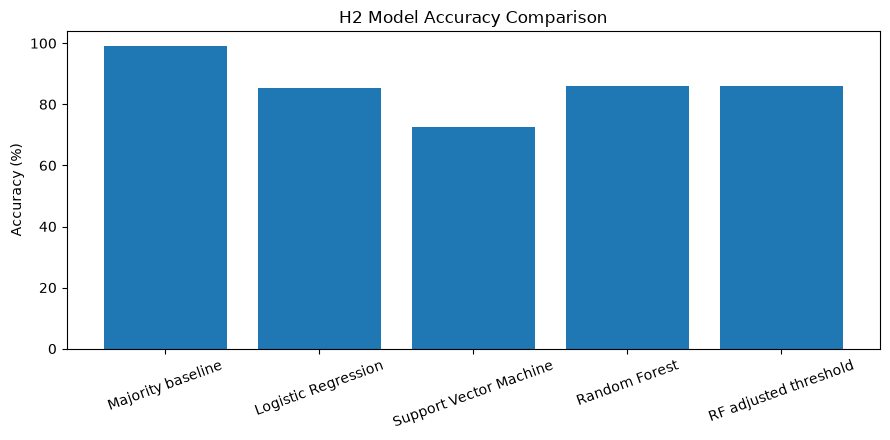

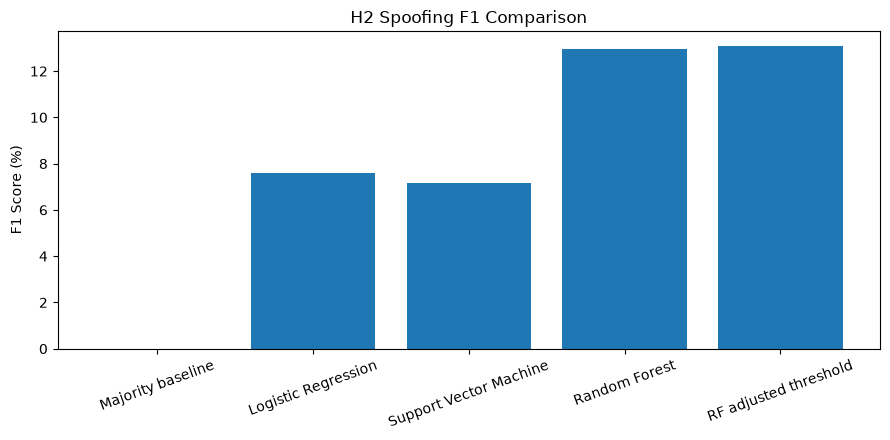

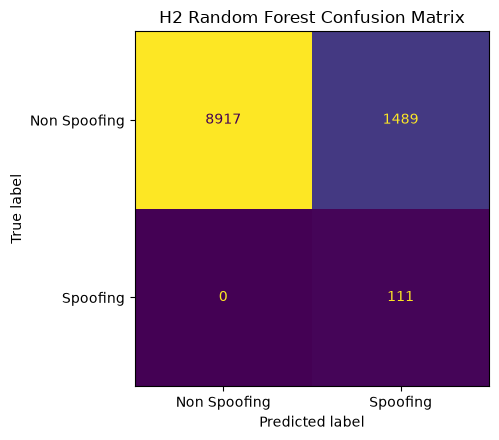

Supplemental H2 results saved to: /workspaces/Aviation-Baggage-Cybersecurity-Research/08_H2_Results
Original Notebook 04 results were not changed.

Step 8 complete.


In [8]:

# Step 8: Verify and save the H2 robustness evidence

# Load the confusion matrix display

from sklearn.metrics import ConfusionMatrixDisplay

# Confirm each model used the same testing records

assert all(
    len(values) == len(y_test)
    for values in predictions.values()
)

# Confirm the training and testing journeys are separate

assert set(groups_train).isdisjoint(
    set(groups_test)
)

# Confirm the five comparisons were completed

assert len(model_comparison) == 5

# Prepare the H2 results folder

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Save the model comparison

model_comparison.to_csv(
    results_folder / "h2_robustness_model_comparison.csv",
    index=False
)

# Save the validation threshold results

threshold_results.to_csv(
    results_folder / "h2_robustness_threshold_validation.csv",
    index=False
)

# Save the false alert analysis

false_alert_review.to_csv(
    results_folder / "h2_robustness_false_alert_review.csv",
    index=False
)

# Save the spoofing pattern results

pattern_review.to_csv(
    results_folder / "h2_robustness_spoofing_patterns.csv",
    index=False
)

# Save the bootstrap intervals

bootstrap_intervals.to_csv(
    results_folder / "h2_robustness_bootstrap_intervals.csv",
    index=False
)

# Save the predictions for individual test scans

test_review.to_csv(
    results_folder / "h2_robustness_test_predictions.csv",
    index=False
)

# Create the accuracy comparison chart

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.bar(
    model_comparison["model"],
    model_comparison["accuracy"] * 100
)

ax.set_title("H2 Model Accuracy Comparison")

ax.set_ylabel("Accuracy (%)")

ax.tick_params(axis="x", rotation=20)

fig.tight_layout()

fig.savefig(
    results_folder / "h2_robustness_accuracy.png",
    dpi=160
)

plt.show()

# Create the spoofing F1 comparison chart

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.bar(
    model_comparison["model"],
    model_comparison["f1"] * 100
)

ax.set_title("H2 Spoofing F1 Comparison")

ax.set_ylabel("F1 Score (%)")

ax.tick_params(axis="x", rotation=20)

fig.tight_layout()

fig.savefig(
    results_folder / "h2_robustness_f1.png",
    dpi=160
)

plt.show()

# Create the Random Forest confusion matrix

fig, ax = plt.subplots(figsize=(5.5, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions["Random Forest"],
    labels=[0, 1],
    display_labels=["Non Spoofing", "Spoofing"],
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title("H2 Random Forest Confusion Matrix")

fig.tight_layout()

fig.savefig(
    results_folder / "h2_robustness_rf_confusion.png",
    dpi=160
)

plt.show()

# Calculate the fingerprint of the original dataset

def file_sha256(path):

    digest = hashlib.sha256()

    with path.open("rb") as source:

        for block in iter(
            lambda: source.read(1024 * 1024),
            b""
        ):

            digest.update(block)

    return digest.hexdigest()

# Record the experiment settings

settings = {
    "source_file": str(
        prepared_file.relative_to(main_folder)
    ),
    "source_sha256": file_sha256(prepared_file),
    "test_records": len(y_test),
    "test_spoofing_records": int(y_test.sum()),
    "test_baggage_journeys": int(
        groups_test.nunique()
    ),
    "group_split_seed": 42,
    "validation_split_seed": 43,
    "random_forest_threshold": best_threshold,
    "bootstrap_resamples": 300,
    "notes": (
        "Simulated RFID data; threshold selected "
        "without final test data"
    )
}

# Save the settings

with (
    results_folder / "h2_robustness_settings.json"
).open("w") as output:

    json.dump(
        settings,
        output,
        indent=2
    )

# Display confirmation

print(
    "Supplemental H2 results saved to:",
    results_folder
)

print("Original Notebook 04 results were not changed.")

print("\nStep 8 complete.")



Step 9: Evaluate Detection of Unfamiliar Spoofing Patterns

The H2 models are challenged with simulated spoofing patterns excluded from training. Each test removes one attack pattern from the training records, while retaining non spoofing records and the other two spoofing patterns. A fresh model is trained for each test. Logistic Regression, Support Vector Machine, and Random Forest use the same remaining training data and the original model settings.

The test records remain separated by baggage journey. Each model is evaluated on the excluded spoofing pattern, the previously observed patterns, and the non spoofing test records. Recall and false positives are reported separately because detecting unusual attacks is not enough if legitimate scans are frequently flagged.

This is a controlled unfamiliar pattern challenge using the same simulated data generator. It does not establish performance against unknown attacks collected in an airport. The default model predictions are used; the threshold selected in Step 4 is not applied to these challenge models.


Unfamiliar Spoofing Pattern Challenge:


,excluded_pattern,model,training_spoofing_scans,unseen_test_scans,unseen_detected,unseen_recall,seen_test_scans,seen_detected,seen_recall,false_positives,false_positive_rate
0,Unauthorized Reader,Logistic Regression,172,33,2,0.0606,78,47,0.6026,1523,0.1464
1,Unauthorized Reader,Support Vector Machine,172,33,2,0.0606,78,78,1.0000,1435,0.1379
2,Unauthorized Reader,Random Forest,172,33,2,0.0606,78,78,1.0000,1471,0.1414
3,Cloned Reader Location,Logistic Regression,182,43,6,0.1395,68,49,0.7206,1508,0.1449
4,Cloned Reader Location,Support Vector Machine,182,43,6,0.1395,68,68,1.0000,1441,0.1385
5,Cloned Reader Location,Random Forest,182,43,6,0.1395,68,68,1.0000,1489,0.1431
6,Replayed Reader Timing,Logistic Regression,174,35,6,0.1714,76,35,0.4605,2946,0.2831
7,Replayed Reader Timing,Support Vector Machine,174,35,6,0.1714,76,76,1.0000,2874,0.2762
8,Replayed Reader Timing,Random Forest,174,35,6,0.1714,76,76,1.0000,1489,0.1431


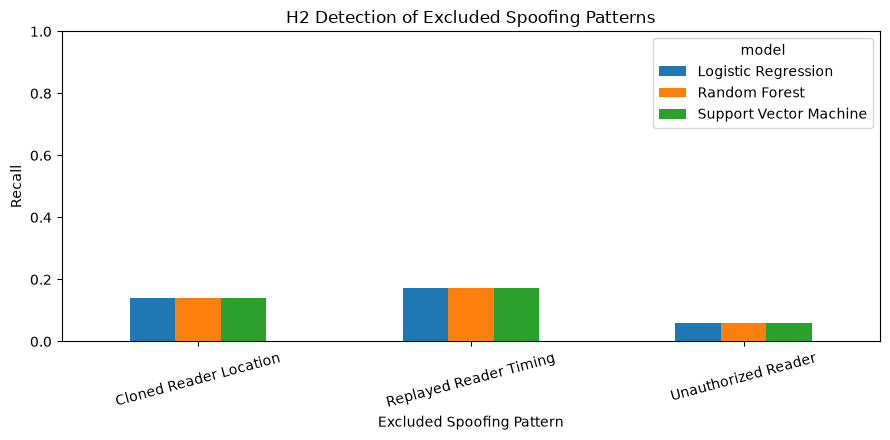

Original Notebook 04 outputs remain unchanged.

Step 9 complete.


In [9]:

# Step 9: Evaluate unfamiliar spoofing patterns

# Identify the three patterns from Notebook 04

spoofing_patterns = [
    "Unauthorized Reader",
    "Cloned Reader Location",
    "Replayed Reader Timing"
]

# Match the patterns to the grouped training records

train_patterns = h2_model_data.iloc[
    train_index
]["spoofing_pattern"].to_numpy()

# Match the patterns to the grouped testing records

test_patterns = h2_model_data.iloc[
    test_index
]["spoofing_pattern"].to_numpy()

# Prepare the training and testing labels

train_labels = y_train.to_numpy()

test_labels = y_test.to_numpy()

# Confirm baggage journeys do not overlap

assert set(groups_train).isdisjoint(
    set(groups_test)
)

# Create a list for the challenge results

challenge_rows = []

# Test each unfamiliar spoofing pattern

for unseen_pattern in spoofing_patterns:

    # Keep every non spoofing training record
    # Keep spoofing records from the other two patterns

    keep = (
        (train_labels == 0)
        | (train_patterns != unseen_pattern)
    )

    # Confirm the excluded pattern is absent from training

    assert not (
        (train_labels[keep] == 1)
        & (train_patterns[keep] == unseen_pattern)
    ).any()

    # Confirm both target classes remain in training

    assert len(
        pd.unique(train_labels[keep])
    ) == 2

    # Prepare training data without the excluded pattern

    challenge_preprocessor = make_preprocessor()

    X_challenge_train = (
        challenge_preprocessor.fit_transform(
            X_train.iloc[keep]
        )
    )

    # Apply the same preparation to held out test data

    X_challenge_test = (
        challenge_preprocessor.transform(
            X_test
        )
    )

    # Identify the unfamiliar spoofing test records

    unseen = (
        (test_labels == 1)
        & (test_patterns == unseen_pattern)
    )

    # Identify spoofing patterns included in training

    seen = (
        (test_labels == 1)
        & (test_patterns != unseen_pattern)
    )

    # Identify the non spoofing records

    normal = test_labels == 0

    # Confirm all evaluation groups contain records

    assert unseen.sum() > 0

    assert seen.sum() > 0

    assert normal.sum() > 0

    # Create three fresh models for this challenge

    challenge_models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ),
        "Support Vector Machine": SVC(
            kernel="rbf",
            class_weight="balanced"
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        )
    }

    # Train and test each model

    for name, model in challenge_models.items():

        # Train without the unfamiliar spoofing pattern

        model.fit(
            X_challenge_train,
            y_train.iloc[keep]
        )

        # Predict on the held out baggage journeys

        predicted = model.predict(
            X_challenge_test
        )

        # Count unfamiliar spoofing detections

        unseen_detected = int(
            predicted[unseen].sum()
        )

        # Count known spoofing detections

        seen_detected = int(
            predicted[seen].sum()
        )

        # Count incorrect spoofing alerts

        false_positives = int(
            predicted[normal].sum()
        )

        # Save the challenge results

        challenge_rows.append({
            "excluded_pattern": unseen_pattern,
            "model": name,
            "training_spoofing_scans": int(
                train_labels[keep].sum()
            ),
            "unseen_test_scans": int(
                unseen.sum()
            ),
            "unseen_detected": unseen_detected,
            "unseen_recall": round(
                unseen_detected / int(unseen.sum()),
                4
            ),
            "seen_test_scans": int(
                seen.sum()
            ),
            "seen_detected": seen_detected,
            "seen_recall": round(
                seen_detected / int(seen.sum()),
                4
            ),
            "false_positives": false_positives,
            "false_positive_rate": round(
                false_positives / int(normal.sum()),
                4
            )
        })

# Create the challenge comparison table

unseen_challenge = pd.DataFrame(
    challenge_rows
)

# Confirm three models were tested on three patterns

assert len(unseen_challenge) == 9

# Display the results

print("Unfamiliar Spoofing Pattern Challenge:")

display(unseen_challenge)

# Save the supplemental challenge results

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

unseen_challenge.to_csv(
    results_folder / "h2_unseen_spoofing_challenge.csv",
    index=False
)

# Create the unfamiliar spoofing comparison chart

fig, ax = plt.subplots(figsize=(9, 4.5))

unseen_challenge.pivot(
    index="excluded_pattern",
    columns="model",
    values="unseen_recall"
).plot(
    kind="bar",
    ax=ax
)

# Label the chart

ax.set_title(
    "H2 Detection of Excluded Spoofing Patterns"
)

ax.set_xlabel("Excluded Spoofing Pattern")

ax.set_ylabel("Recall")

ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=15
)

fig.tight_layout()

# Save the chart

fig.savefig(
    results_folder / "h2_unseen_spoofing_challenge.png",
    dpi=160
)

plt.show()

print("Original Notebook 04 outputs remain unchanged.")

print("\nStep 9 complete.")



Step 10: Investigate Validation and Testing Differences

The Random Forest validation model achieved perfect classification on the selected validation population, while the final testing results showed substantially lower precision and F1 performance.

The validation model is evaluated on the held out test journeys to examine whether the difference is related to the testing population or the final training process.

The same selected threshold is retained. No threshold or model setting is changed using the final testing records.

This diagnostic analysis examines the consistency of the experimental findings before the results are interpreted for H2.


In [10]:

# Step 10: Investigate validation and testing differences

# Apply the validation preprocessing to final test records

validation_test_ready = (
    validation_preprocessor.transform(X_test)
)

# Calculate predictions using the validation model

validation_test_scores = (
    validation_forest.predict_proba(
        validation_test_ready
    )[:, positive_column]
)

# Apply the threshold selected in Step 4

validation_test_predictions = (
    validation_test_scores >= best_threshold
).astype(int)

# Recreate predictions on validation records

validation_predictions = (
    validation_scores >= best_threshold
).astype(int)

# Compare the validation and test results

diagnostic_rows = []

for name, actual, predicted in [
    (
        "Validation population",
        y_validation,
        validation_predictions
    ),
    (
        "Final test using validation model",
        y_test,
        validation_test_predictions
    ),
    (
        "Final test using full training model",
        y_test,
        predictions["Random Forest"]
    )
]:

    # Calculate the classification errors

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    # Record the performance measurements

    diagnostic_rows.append({
        "population": name,
        "records": len(actual),
        "spoofing_records": int(actual.sum()),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "f1": f1_score(
            actual, predicted, zero_division=0
        ),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

# Display the diagnostic results

validation_diagnostic = pd.DataFrame(
    diagnostic_rows
)

print("H2 Validation and Test Diagnostic:")

display(validation_diagnostic.round(4))

print("\nOriginal model results remain unchanged.")

print("\nStep 10 complete.")


H2 Validation and Test Diagnostic:


,population,records,spoofing_records,accuracy,precision,recall,f1,false_positives,false_negatives
0,Validation population,5267,65,1.0000,1.0000,1.0,1.0000,0,0
1,Final test using validation model,10517,111,0.8596,0.0699,1.0,0.1307,1477,0
2,Final test using full training model,10517,111,0.8584,0.0694,1.0,0.1297,1489,0



Original model results remain unchanged.

Step 10 complete.


In [11]:

# Review the H2 validation and testing results

# Confirm the diagnostic analysis was completed

if "validation_diagnostic" in globals():

    print("H2 Validation and Testing Comparison:")

    display(validation_diagnostic.round(4))

    print("\nDiagnostic review complete.")

else:

    print("Please run Step 10 first.")


H2 Validation and Testing Comparison:


,population,records,spoofing_records,accuracy,precision,recall,f1,false_positives,false_negatives
0,Validation population,5267,65,1.0000,1.0000,1.0,1.0000,0,0
1,Final test using validation model,10517,111,0.8596,0.0699,1.0,0.1307,1477,0
2,Final test using full training model,10517,111,0.8584,0.0694,1.0,0.1297,1489,0



Diagnostic review complete.



Step 11: Examine Data Distribution and False Positive Differences

The validation results showed no incorrect spoofing alerts, while the final testing population produced a substantial number of false positives.

The analysis compares both populations using the same trained Random Forest validation model. It examines scan conditions, route types, and timing measurements to identify possible differences between the two populations.

The results are used to determine whether the performance difference may be associated with the composition of the data or the characteristics of legitimate baggage activity.

This diagnostic does not change the original labels, training records, model settings, or detection results.

In [12]:

# Step 11: Examine validation and testing differences

# Select the original records for both populations

validation_review = h2_model_data.loc[
    X_validation.index
].copy()

final_test_review = h2_model_data.loc[
    X_test.index
].copy()

# Confirm the labels match the model records

assert np.array_equal(
    validation_review["spoofing_label"].to_numpy(),
    y_validation.to_numpy()
)

assert np.array_equal(
    final_test_review["spoofing_label"].to_numpy(),
    y_test.to_numpy()
)

# Add predictions from the same validation model

validation_review["prediction"] = (
    validation_predictions
)

final_test_review["prediction"] = (
    validation_test_predictions
)

# Identify the evaluation populations

validation_review["population"] = "Validation"

final_test_review["population"] = "Final Test"

# Combine the review records

combined_review = pd.concat(
    [validation_review, final_test_review],
    ignore_index=True
)

# Identify incorrect spoofing alerts

combined_review["false_positive"] = (
    (combined_review["spoofing_label"] == 0)
    & (combined_review["prediction"] == 1)
).astype(int)

# Compare the scan status distributions

status_review = (
    combined_review.loc[
        combined_review["spoofing_label"] == 0
    ]
    .groupby(
        ["population", "scan_status"],
        dropna=False
    )
    .agg(
        nonspoofing_scans=("scan_id", "count"),
        false_positives=("false_positive", "sum")
    )
    .reset_index()
)

# Calculate the false positive rate for each condition

status_review["false_positive_rate"] = (
    status_review["false_positives"]
    / status_review["nonspoofing_scans"]
)

# Compare baggage route types

route_review = (
    combined_review.loc[
        combined_review["spoofing_label"] == 0
    ]
    .groupby(
        ["population", "route_type"],
        dropna=False
    )
    .agg(
        nonspoofing_scans=("scan_id", "count"),
        false_positives=("false_positive", "sum")
    )
    .reset_index()
)

# Calculate false positive rates by route

route_review["false_positive_rate"] = (
    route_review["false_positives"]
    / route_review["nonspoofing_scans"]
)

# Compare timing characteristics

timing_review = (
    combined_review.loc[
        combined_review["spoofing_label"] == 0
    ]
    .groupby("population")
    .agg(
        median_time_difference=(
            "time_difference_minutes",
            "median"
        ),
        median_scan_gap=(
            "scan_gap_minutes",
            "median"
        ),
        delayed_scans=(
            "delayed_indicator",
            "sum"
        )
    )
    .reset_index()
)

# Display the diagnostic results

print("False Positives by Scan Status:")

display(status_review.round(4))

print("\nFalse Positives by Route Type:")

display(route_review.round(4))

print("\nTiming Comparison:")

display(timing_review.round(4))

# Save the additional research evidence

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

status_review.to_csv(
    results_folder / "h2_validation_test_scan_status.csv",
    index=False
)

route_review.to_csv(
    results_folder / "h2_validation_test_route_comparison.csv",
    index=False
)

timing_review.to_csv(
    results_folder / "h2_validation_test_timing.csv",
    index=False
)

print("\nStep 11 complete.")


False Positives by Scan Status:


,population,scan_status,nonspoofing_scans,false_positives,false_positive_rate
0,Final Test,Delayed,63,0,0.0000
1,Final Test,Denial of Service,30,3,0.1000
2,Final Test,Duplicate,57,10,0.1754
3,Final Test,Invalid Location,72,6,0.0833
4,Final Test,Normal,10114,1446,0.1430
5,Final Test,Out of Sequence,70,12,0.1714
6,Validation,Delayed,45,0,0.0000
7,Validation,Denial of Service,6,0,0.0000
8,Validation,Duplicate,46,0,0.0000
9,Validation,Invalid Location,38,0,0.0000



False Positives by Route Type:


,population,route_type,nonspoofing_scans,false_positives,false_positive_rate
0,Final Test,Transfer,10406,1477,0.1419
1,Validation,Direct,5202,0,0.0000



Timing Comparison:


,population,median_time_difference,median_scan_gap,delayed_scans
0,Final Test,0.0,10.0,63
1,Validation,0.0,10.0,45



Step 11 complete.



Step 12: Prepare a Route Balanced Model Evaluation

The original H2 evaluation separated baggage journeys into training and testing populations that contained different route types. The validation population contained direct routes, while the final testing population contained transfer routes.

A supplemental evaluation is prepared to determine whether model performance changes when direct and transfer journeys are represented in both populations.

Baggage journeys are separated before modeling to prevent records from the same journey appearing in training and testing. A separate validation population is also created for model selection.

The original model settings are retained, and no additional tuning is performed using the new testing records.


In [13]:

# Step 12: Prepare a route balanced evaluation

# Load the data splitting method

from sklearn.model_selection import train_test_split

# Identify each baggage journey and its route

journeys = h2_model_data[
    ["bag_id", "route_type"]
].drop_duplicates().copy()

# Confirm each baggage journey has one route type

assert journeys["bag_id"].is_unique

# Separate baggage journeys while balancing route types

train_bags, test_bags = train_test_split(
    journeys["bag_id"],
    test_size=0.30,
    random_state=2026,
    stratify=journeys["route_type"]
)

# Create a mask for the new training population

train_mask = h2_model_data["bag_id"].isin(
    train_bags
)

# Create a mask for the new testing population

test_mask = h2_model_data["bag_id"].isin(
    test_bags
)

# Prepare the predictor and target records

X_bal_train = X.loc[train_mask].copy()
y_bal_train = y.loc[train_mask].copy()

X_bal_test = X.loc[test_mask].copy()
y_bal_test = y.loc[test_mask].copy()

# Confirm no baggage journey appears in both populations

assert set(train_bags).isdisjoint(
    set(test_bags)
)

# Confirm both populations contain spoofing records

assert int(y_bal_train.sum()) > 0
assert int(y_bal_test.sum()) > 0

# Display the new route distribution

print("Route Balanced Training Population:")

print(
    h2_model_data.loc[
        train_mask, "route_type"
    ].value_counts()
)

print("\nRoute Balanced Testing Population:")

print(
    h2_model_data.loc[
        test_mask, "route_type"
    ].value_counts()
)

# Display the total number of records

print("\nTraining scans:", len(X_bal_train))
print("Testing scans:", len(X_bal_test))

print(
    "Training spoofing scans:",
    int(y_bal_train.sum())
)

print(
    "Testing spoofing scans:",
    int(y_bal_test.sum())
)

print("\nShared baggage journeys: 0")

print("\nStep 12 complete.")


Route Balanced Training Population:
route_type
Direct      14746
Transfer     7360
Name: count, dtype: int64

Route Balanced Testing Population:
route_type
Direct      6312
Transfer    3157
Name: count, dtype: int64

Training scans: 22106
Testing scans: 9469
Training spoofing scans: 259
Testing spoofing scans: 116

Shared baggage journeys: 0

Step 12 complete.



Step 13: Compare Machine Learning Performance Across Baggage Routes

The route balanced training and testing populations are used to repeat the H2 model comparison. Both populations contain direct and transfer baggage journeys, allowing model performance to be evaluated across different operating conditions.

Logistic Regression, Support Vector Machine, and Random Forest are trained using the original predictor fields and model settings. A majority class baseline is included to provide a comparison for the imbalanced spoofing labels.

Accuracy, precision, recall, F1 score, balanced accuracy, and false positives are calculated for the overall testing population. Performance is also examined separately for direct and transfer baggage routes.

The original model settings are retained without tuning against the new testing records. The resulting comparison is a supplemental sensitivity analysis using the existing simulated RFID dataset. It does not represent independent validation with newly collected airport records.

In [14]:

# Step 13: Compare Machine Learning models across baggage routes

# Load the Machine Learning models

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Load the evaluation measures

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Prepare the balanced training data

balanced_preprocessor = make_preprocessor()

X_bal_train_ready = balanced_preprocessor.fit_transform(
    X_bal_train
)

# Apply the same preparation to the testing data

X_bal_test_ready = balanced_preprocessor.transform(
    X_bal_test
)

# Create models using the original settings

balanced_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Support Vector Machine": SVC(
        kernel="rbf",
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

# Determine the majority training class

balanced_majority_label = int(
    y_bal_train.mode().iloc[0]
)

# Create majority baseline predictions

balanced_predictions = {
    "Majority baseline": np.full(
        len(y_bal_test),
        balanced_majority_label
    )
}

# Train each model and predict on the testing records

for name, model in balanced_models.items():

    # Train using the route balanced training population

    model.fit(
        X_bal_train_ready,
        y_bal_train
    )

    # Store predictions for the testing population

    balanced_predictions[name] = model.predict(
        X_bal_test_ready
    )

# Define the performance evaluation function

def evaluate_balanced_model(name, actual, predicted, route):

    # Calculate the confusion matrix

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    # Return the performance measurements

    return {
        "model": name,
        "route_type": route,
        "test_records": len(actual),
        "spoofing_records": int(np.sum(actual)),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "f1": f1_score(
            actual, predicted, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "false_positive_rate": (
            fp / (fp + tn) if (fp + tn) else 0
        ),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_negatives": int(tn)
    }

# Get the actual testing labels

balanced_actual = y_bal_test.to_numpy()

# Identify the route type of each testing scan

balanced_test_routes = h2_model_data.loc[
    X_bal_test.index,
    "route_type"
].to_numpy()

# Create the overall evaluation table

balanced_results = pd.DataFrame([
    evaluate_balanced_model(
        name,
        balanced_actual,
        predicted,
        "Overall"
    )
    for name, predicted in balanced_predictions.items()
])

# Create a list for the individual route results

balanced_route_rows = []

# Examine direct and transfer routes separately

for route in ["Direct", "Transfer"]:

    # Find the records belonging to this route

    route_mask = balanced_test_routes == route

    # Confirm the route contains testing records

    assert route_mask.sum() > 0

    # Evaluate each model on this route

    for name, predicted in balanced_predictions.items():

        balanced_route_rows.append(
            evaluate_balanced_model(
                name,
                balanced_actual[route_mask],
                np.asarray(predicted)[route_mask],
                route
            )
        )

# Create the individual route comparison table

balanced_route_results = pd.DataFrame(
    balanced_route_rows
)

# Display the overall results

print("Route Balanced H2 Model Comparison:")

display(balanced_results.round(4))

# Display the results for each baggage route

print("\nPerformance by Baggage Route:")

display(balanced_route_results.round(4))

# Save the new results without modifying earlier experiments

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

balanced_results.to_csv(
    results_folder / "h2_route_balanced_model_comparison.csv",
    index=False
)

balanced_route_results.to_csv(
    results_folder / "h2_route_balanced_route_comparison.csv",
    index=False
)

# Confirm the analysis completed

print("\nRoute balanced model comparison complete.")

print("Original H2 results remain unchanged.")

print("\nStep 13 complete.")


Route Balanced H2 Model Comparison:


,model,route_type,test_records,spoofing_records,accuracy,precision,recall,f1,balanced_accuracy,false_positive_rate,true_positives,false_positives,false_negatives,true_negatives
0,Majority baseline,Overall,9469,116,0.9877,0.0000,0.0000,0.0000,0.5000,0.0000,0,0,116,9353
1,Logistic Regression,Overall,9469,116,0.9858,0.4297,0.4741,0.4508,0.7332,0.0078,55,73,61,9280
2,Support Vector Machine,Overall,9469,116,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,116,0,0,9353
3,Random Forest,Overall,9469,116,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,116,0,0,9353



Performance by Baggage Route:


,model,route_type,test_records,spoofing_records,accuracy,precision,recall,f1,balanced_accuracy,false_positive_rate,true_positives,false_positives,false_negatives,true_negatives
0,Majority baseline,Direct,6312,85,0.9865,0.0000,0.0000,0.0000,0.5000,0.0000,0,0,85,6227
1,Logistic Regression,Direct,6312,85,0.9846,0.4412,0.5294,0.4813,0.7601,0.0092,45,57,40,6170
2,Support Vector Machine,Direct,6312,85,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,85,0,0,6227
3,Random Forest,Direct,6312,85,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,85,0,0,6227
4,Majority baseline,Transfer,3157,31,0.9902,0.0000,0.0000,0.0000,0.5000,0.0000,0,0,31,3126
5,Logistic Regression,Transfer,3157,31,0.9883,0.3846,0.3226,0.3509,0.6587,0.0051,10,16,21,3110
6,Support Vector Machine,Transfer,3157,31,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,31,0,0,3126
7,Random Forest,Transfer,3157,31,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,31,0,0,3126



Route balanced model comparison complete.
Original H2 results remain unchanged.

Step 13 complete.



Step 14: Evaluate Unfamiliar Spoofing Under Route Balanced Conditions

The original unfamiliar spoofing experiment was conducted using training and testing populations with different baggage route distributions. The route balanced evaluation provides a separate comparison in which direct and transfer journeys appear in both populations.

Each spoofing pattern is excluded from training one at a time. Logistic Regression, Support Vector Machine, and Random Forest are trained using the two remaining spoofing patterns and non spoofing records.

The models are then evaluated using held out baggage journeys. Detection recall is measured for unfamiliar and previously observed spoofing patterns. False positives are also recorded.

The analysis determines whether the earlier unfamiliar spoofing results were affected by the difference between baggage routes. The same simulated RFID dataset and original model settings are retained. No previously reported results are replaced.

In [15]:

# Step 14: Evaluate unfamiliar spoofing using route balanced data

# Identify spoofing patterns in the balanced populations

balanced_train_patterns = h2_model_data.loc[
    X_bal_train.index, "spoofing_pattern"
].to_numpy()

balanced_test_patterns = h2_model_data.loc[
    X_bal_test.index, "spoofing_pattern"
].to_numpy()

# Prepare the known labels

balanced_train_labels = y_bal_train.to_numpy()

balanced_test_labels = y_bal_test.to_numpy()

# Confirm baggage journeys are separate

assert set(
    h2_model_data.loc[X_bal_train.index, "bag_id"]
).isdisjoint(
    set(h2_model_data.loc[X_bal_test.index, "bag_id"])
)

# Create a list for the results

balanced_challenge_rows = []

# Evaluate each excluded spoofing pattern

for unseen_pattern in spoofing_patterns:

    # Remove one spoofing pattern from training

    keep = (
        (balanced_train_labels == 0)
        | (balanced_train_patterns != unseen_pattern)
    )

    # Confirm no excluded attack records remain

    assert not (
        (balanced_train_labels[keep] == 1)
        & (balanced_train_patterns[keep] == unseen_pattern)
    ).any()

    # Identify unfamiliar attacks in testing

    unseen = (
        (balanced_test_labels == 1)
        & (balanced_test_patterns == unseen_pattern)
    )

    # Identify known attacks in testing

    seen = (
        (balanced_test_labels == 1)
        & (balanced_test_patterns != unseen_pattern)
    )

    # Identify records without the spoofing label

    nonspoofing = balanced_test_labels == 0

    # Confirm all test groups contain records

    assert unseen.sum() > 0
    assert seen.sum() > 0
    assert nonspoofing.sum() > 0

    # Prepare training and testing data separately

    challenge_preprocessor = make_preprocessor()

    prepared_train = challenge_preprocessor.fit_transform(
        X_bal_train.iloc[keep]
    )

    prepared_test = challenge_preprocessor.transform(
        X_bal_test
    )

    # Create the three models using original settings

    challenge_models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ),
        "Support Vector Machine": SVC(
            kernel="rbf",
            class_weight="balanced"
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        )
    }

    # Evaluate each model

    for name, model in challenge_models.items():

        # Train without the excluded spoofing pattern

        model.fit(
            prepared_train,
            y_bal_train.iloc[keep]
        )

        # Predict against the balanced test population

        predicted = model.predict(prepared_test)

        # Count correct detections and incorrect alerts

        unseen_detected = int(predicted[unseen].sum())

        seen_detected = int(predicted[seen].sum())

        false_positives = int(
            predicted[nonspoofing].sum()
        )

        # Store the results

        balanced_challenge_rows.append({
            "excluded_pattern": unseen_pattern,
            "model": name,
            "unseen_test_scans": int(unseen.sum()),
            "unseen_detected": unseen_detected,
            "unseen_recall": round(
                unseen_detected / int(unseen.sum()), 4
            ),
            "seen_test_scans": int(seen.sum()),
            "seen_recall": round(
                seen_detected / int(seen.sum()), 4
            ),
            "false_positives": false_positives,
            "false_positive_rate": round(
                false_positives / int(nonspoofing.sum()), 4
            )
        })

# Create the final challenge table

balanced_unseen_results = pd.DataFrame(
    balanced_challenge_rows
)

# Confirm three models and three patterns were evaluated

assert len(balanced_unseen_results) == 9

# Display the results

print("Route Balanced Unfamiliar Spoofing Challenge:")

display(balanced_unseen_results)

# Save the results without changing previous outputs

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

balanced_unseen_results.to_csv(
    results_folder
    / "h2_route_balanced_unseen_spoofing_challenge.csv",
    index=False
)

print("\nStep 14 complete.")


Route Balanced Unfamiliar Spoofing Challenge:


,excluded_pattern,model,unseen_test_scans,unseen_detected,unseen_recall,seen_test_scans,seen_recall,false_positives,false_positive_rate
0,Unauthorized Reader,Logistic Regression,38,0,0.0,78,0.5897,29,0.0031
1,Unauthorized Reader,Support Vector Machine,38,0,0.0,78,0.9872,0,0.0000
2,Unauthorized Reader,Random Forest,38,0,0.0,78,1.0000,0,0.0000
3,Cloned Reader Location,Logistic Regression,39,0,0.0,77,0.5584,16,0.0017
4,Cloned Reader Location,Support Vector Machine,39,0,0.0,77,1.0000,0,0.0000
5,Cloned Reader Location,Random Forest,39,0,0.0,77,1.0000,0,0.0000
6,Replayed Reader Timing,Logistic Regression,39,0,0.0,77,0.3896,1907,0.2039
7,Replayed Reader Timing,Support Vector Machine,39,0,0.0,77,1.0000,0,0.0000
8,Replayed Reader Timing,Random Forest,39,0,0.0,77,1.0000,0,0.0000



Step 14 complete.



Step 15: Examine Feature Signals and Simple Verification Rules

The route balanced experiments classified known spoofing patterns successfully but failed to identify every excluded pattern. This diagnostic examines whether the simulated attacks create recognizable differences in reader identity, reader location, and scan timing.

The analysis reviews these signals on the held out route balanced test records. It also tests a simple identity and location verification rule to examine whether direct comparisons detect spoofing without a Machine Learning model. The rule uses the expected reader identity, which was not among the 13 H2 model predictors, so its result is not a matched model comparison.

The diagnostic does not alter the simulated records or the original model findings. The resulting patterns describe the researcher's attack construction and must not be presented as independent evidence that the models can detect real airport attacks.

In [16]:

# Step 15: Examine feature signals and simple verification rules

# Select the held out route balanced testing records

audit = h2_model_data.loc[X_bal_test.index, [
    "spoofing_pattern",
    "spoofing_label",
    "route_type",
    "reader_id",
    "expected_reader_id",
    "reader_location",
    "expected_reader_location",
    "time_difference_minutes"
]].copy()

# Confirm the rows match the testing labels

assert np.array_equal(
    audit["spoofing_label"].to_numpy(),
    y_bal_test.to_numpy()
)

# Identify reader identity differences

audit["reader_identity_mismatch"] = (
    audit["reader_id"] != audit["expected_reader_id"]
).astype(int)

# Identify reader location differences

audit["reader_location_mismatch"] = (
    audit["reader_location"]
    != audit["expected_reader_location"]
).astype(int)

# Identify timing offsets of at least five minutes
# This cutoff describes the generated replay pattern
# It is not a separately validated security threshold

audit["timing_offset_5_minutes"] = (
    audit["time_difference_minutes"] >= 5
).astype(int)

# Summarize the observed signals for each attack pattern

feature_audit = (
    audit.groupby("spoofing_pattern")
    .agg(
        test_scans=("spoofing_label", "size"),
        reader_identity_mismatches=(
            "reader_identity_mismatch", "sum"
        ),
        reader_location_mismatches=(
            "reader_location_mismatch", "sum"
        ),
        timing_offsets_5_minutes=(
            "timing_offset_5_minutes", "sum"
        ),
        median_timing_difference_minutes=(
            "time_difference_minutes", "median"
        )
    )
    .reset_index()
)

# Create a simple reader and location verification rule
# The expected reader identity is not an H2 model predictor

audit["simple_verification_alert"] = (
    (audit["reader_identity_mismatch"] == 1)
    | (audit["reader_location_mismatch"] == 1)
).astype(int)

# Measure this diagnostic rule against the spoofing label

truth = audit["spoofing_label"].to_numpy()
rule_pred = audit["simple_verification_alert"].to_numpy()

tn, fp, fn, tp = confusion_matrix(
    truth, rule_pred, labels=[0, 1]
).ravel()

rule_review = pd.DataFrame([{
    "diagnostic": "Reader identity or location mismatch",
    "accuracy": accuracy_score(truth, rule_pred),
    "precision": precision_score(
        truth, rule_pred, zero_division=0
    ),
    "recall": recall_score(
        truth, rule_pred, zero_division=0
    ),
    "f1": f1_score(
        truth, rule_pred, zero_division=0
    ),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
    "true_negatives": int(tn)
}])

# Verify that known labels and direct comparison results
# were not used as Machine Learning predictors

excluded_fields = {
    "spoofing_label",
    "spoofing_pattern",
    "reader_match",
    "location_match"
}

assert excluded_fields.isdisjoint(set(feature_fields))

# Display the feature audit and simple verification results

print("Simulated Spoofing Feature Signal Audit:")
display(feature_audit.round(4))

print("\nSimple Identity and Location Rule Diagnostic:")
display(rule_review.round(4))

print("\nH2 predictor count:", len(feature_fields))
print("Known target and direct match fields excluded: Yes")
print("Rule uses expected reader identity outside H2 predictors.")

# Save only new results without replacing earlier evidence

results_folder.mkdir(parents=True, exist_ok=True)

feature_audit.to_csv(
    results_folder / "h2_spoofing_feature_signal_audit.csv",
    index=False
)

rule_review.to_csv(
    results_folder / "h2_simple_verification_diagnostic.csv",
    index=False
)

print("\nStep 15 complete.")


Simulated Spoofing Feature Signal Audit:


,spoofing_pattern,test_scans,reader_identity_mismatches,reader_location_mismatches,timing_offsets_5_minutes,median_timing_difference_minutes
0,Cloned Reader Location,39,0,39,0,0.0
1,Non Spoofing,9353,0,72,82,0.0
2,Replayed Reader Timing,39,0,0,39,8.0
3,Unauthorized Reader,38,38,0,0,0.0



Simple Identity and Location Rule Diagnostic:


,diagnostic,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
0,Reader identity or location mismatch,0.9883,0.5168,0.6638,0.5811,72,39,77,9281



H2 predictor count: 13
Known target and direct match fields excluded: Yes
Rule uses expected reader identity outside H2 predictors.

Step 15 complete.



H2 Robustness Findings and Research Interpretation

Notebook 12 evaluates H2 using a majority class baseline, validation selected Random Forest threshold, error review, grouped bootstrap intervals, and unfamiliar spoofing pattern challenges. The majority class baseline provides context for accuracy when spoofing is uncommon. Precision, recall, F1 score, and false positives must be interpreted together rather than selecting a model using accuracy alone.

The unfamiliar pattern challenge withholds one researcher generated spoofing pattern from training at a time. This tests generalization across the three simulated patterns while keeping baggage journeys separated between training and testing. Because all patterns originate from one generator, this does not establish detection of previously unobserved real airport threats.

The threshold is selected on a separate validation portion of the training journeys. The held out test data are not used to choose that threshold. The unfamiliar pattern challenges use the original model prediction settings instead of the threshold tuned using all three training patterns.

The grouped bootstrap estimates uncertainty within the simulated test population. It is not an independent validation dataset. Results from Steps 5 through 9 must be inserted after the notebook has been executed and verified. The findings may support, qualify, or challenge the original H2 determination. No performance result should be assumed before execution.

The research data and original Notebook 04 outputs remain unchanged.
